In [1]:
import pandas as pd
# Install spacy
## -q is for "quiet". It removes logs
!pip install spacy -q
# Import spacy, if you don't have it --> !pip install spacy
import spacy
spacy.__version__
# Download model
!python -m spacy download en_core_web_sm -q
# Import english stop words
from spacy.lang.en.stop_words import STOP_WORDS

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [2]:
data = pd.read_csv('data.csv')

In [3]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['description'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))

# Ajouter des stop words personnalisés
# nlp.Defaults.stop_words.update({"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"})

# # Appliquer les modifications au vocabulaire
# for word in {"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"}:
#     nlp.vocab[word].is_stop = True

Tokens: ['Active', 'classic', 'boxers', '-', 'There', "'s", 'a', 'reason', 'why', 'our', 'boxers', 'are', 'a', 'cult', 'favorite', '-', 'they', 'keep', 'their', 'cool', ',', 'especially', 'in', 'sticky', 'situations', '.', 'The', 'quick', '-', 'drying', ',', 'lightweight', 'underwear', 'takes', 'up', 'minimal', 'space', 'in', 'a', 'travel', 'pack', '.', 'An', 'exposed', ',', 'brushed', 'waistband', 'offers', 'next', '-', 'to', '-', 'skin', 'softness', ',', 'five', '-', 'panel', 'construction', 'with', 'a', 'traditional', 'boxer', 'back', 'for', 'a', 'classic', 'fit', ',', 'and', 'a', 'functional', 'fly', '.', 'Made', 'of', '3.7', '-', 'oz', '100', '%', 'recycled', 'polyester', 'with', 'moisture', '-', 'wicking', 'performance', '.', 'Inseam', '(', 'size', 'M', ')', 'is', '4', '1/2', '"', '.', 'Recyclable', 'through', 'the', 'Common', 'Threads', 'Recycling', 'Program.<br><br><b', '>', 'Details:</b><ul', '>', '<', 'li>"Silky', 'Capilene', '1', 'fabric', 'is', 'ultralight', ',', 'breathabl

In [4]:
# Print stop words
print(STOP_WORDS)

{'should', 'were', 'being', 'make', 'enough', 'across', 'himself', 'part', 'always', 'have', 'hereby', 'whatever', 'do', 'any', 'behind', 'bottom', 'whereas', 'through', 'either', 'might', 'then', 'indeed', 'wherever', '’d', 'fifty', 'around', 'whereupon', 'several', 're', '‘ve', 'nobody', 'even', 'using', 'nine', 'nowhere', 'thereafter', 'twenty', 'will', '’ve', 'amongst', 'than', 'n‘t', 'would', 'on', 'thus', 'take', 'therein', 'often', 'yourselves', 'still', 'whence', 'afterwards', 'without', 'while', 'somewhere', 'same', 'hence', 'there', 'no', 'between', 'within', 'am', 'could', 'as', 'seemed', 'in', 'just', '‘ll', '’ll', 'since', 'yet', 'ca', 'go', 'itself', 'during', 'everything', 'already', "'re", 'more', 'latterly', 'beforehand', 'further', 'regarding', 'such', 'beside', 'hundred', 'down', 'not', 'towards', 'last', 'and', 'whereby', 'ten', 'become', 'along', '’s', 'somehow', 'eight', 'when', 'together', 'beyond', 'amount', 'sixty', 'that', 'besides', 'my', 'third', 'these', 'o

In [5]:
# Install wordcloud if necessary
# !pip install wordcloud -q

In [63]:
wordcloud.WordCloud?

Init signature:
wordcloud.WordCloud(
    font_path=None,
    width=400,
    height=200,
    margin=2,
    ranks_only=None,
    prefer_horizontal=0.9,
    mask=None,
    scale=1,
    color_func=None,
    max_words=200,
    min_font_size=4,
    stopwords=None,
    random_state=None,
    background_color='black',
    max_font_size=None,
    font_step=1,
    mode='RGB',
    relative_scaling='auto',
    regexp=None,
    collocations=True,
    colormap=None,
    normalize_plurals=True,
    contour_width=0,
    contour_color='black',
    repeat=False,
    include_numbers=False,
    min_word_length=0,
    collocation_threshold=30,
)
Docstring:     
Word cloud object for generating and drawing.

Parameters
----------
font_path : string
    Font path to the font that will be used (OTF or TTF).
    Defaults to DroidSansMono path on a Linux machine. If you are on
    another OS or don't have this font, you need to adjust this path.

width : int (default=400)
    Width of the canvas.

height : int 

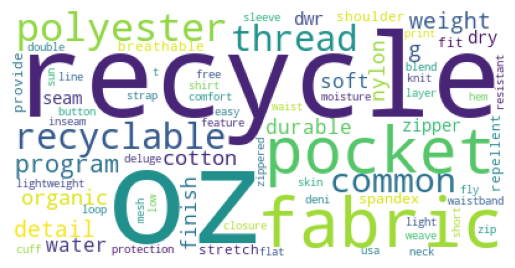

In [64]:
import re
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud
from spacy.lang.en.stop_words import STOP_WORDS

text = " ".join(data['description'].astype(str))
text = re.sub(r"<[^>]+>", " ", text) # replace html
text = re.sub(r"[!\"#$%&()*+,-./:;<=>?@[\\\]^_`{|}~]+", " ", text).lower() # lowercase and punctuation
text = re.sub(r" {2,}", " ", text).strip(" ") # remove concatened spaces and spaces before and after strings

doc = nlp(text)
lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]
lemma

cloud = wordcloud.WordCloud(
    stopwords=STOP_WORDS, 
    collocations=False, 
    min_font_size=6,
    background_color="white", 
    colormap="viridis"
).generate(" ".join(lemma)) # remove bigrams and stopwords

# Show word cloud with matplotlib
plt.imshow(cloud)
plt.axis("off")

# Remove trailing logs
plt.show()

In [8]:
lemma

['active',
 'classic',
 'boxer',
 'reason',
 'boxer',
 'cult',
 'favorite',
 'cool',
 'especially',
 'sticky',
 'situation',
 'quick',
 'dry',
 'lightweight',
 'underwear',
 'minimal',
 'space',
 'travel',
 'pack',
 'expose',
 'brush',
 'waistband',
 'offer',
 'skin',
 'softness',
 'panel',
 'construction',
 'traditional',
 'boxer',
 'classic',
 'fit',
 'functional',
 'fly',
 '3',
 '7',
 'oz',
 '100',
 'recycled',
 'polyester',
 'moisture',
 'wicke',
 'performance',
 'inseam',
 'size',
 'm',
 '4',
 '1',
 '2',
 'recyclable',
 'common',
 'thread',
 'recycle',
 'program',
 'detail',
 'silky',
 'capilene',
 '1',
 'fabric',
 'ultralight',
 'breathable',
 'quick',
 'dry',
 'expose',
 'brush',
 'elastic',
 'waistband',
 'comfort',
 '5',
 'panel',
 'construction',
 'traditional',
 'boxer',
 'inseam',
 'size',
 'm',
 '4',
 '1',
 '2',
 'fabric',
 '3',
 '7',
 'oz',
 '100',
 'recycle',
 'polyester',
 'gladiodor',
 'natural',
 'odor',
 'control',
 'garment',
 'recyclable',
 'common',
 'thread',
 'r

In [9]:
from collections import Counter; Counter(lemma).most_common(30)

[('oz', 1147),
 ('recycle', 1119),
 ('fabric', 1000),
 ('pocket', 844),
 ('polyester', 708),
 ('recyclable', 704),
 ('thread', 686),
 ('common', 684),
 ('program', 683),
 ('detail', 562),
 ('100', 552),
 ('weight', 541),
 ('g', 513),
 ('4', 482),
 ('organic', 454),
 ('cotton', 446),
 ('5', 439),
 ('3', 415),
 ('soft', 398),
 ('water', 391),
 ('2', 380),
 ('durable', 379),
 ('nylon', 364),
 ('finish', 349),
 ('zipper', 342),
 ('dwr', 336),
 ('dry', 330),
 ('seam', 317),
 ('spandex', 312),
 ('stretch', 269)]

La taille d’un mot dépend de sa fréquence dans le texte : plus il est gros, plus il apparaît souvent. La position, l’orientation et la couleur sont aléatoires et n’ont aucune signification. dwr signifie Durable Water Repellent. g pourrait mesurer le poids. 

Prochaines étapes 
puis data mining avec tf idf
retirer le bruit

In [ ]:
# # import displacy
# from spacy import displacy

# # render displacy
# sample = nlp(data['description'].astype(str).iloc[0])
# displacy.render(list(sample.sents)[0], style='dep', jupyter=True,options={'distance': 70})

# text mining

## create an array of odcuments

In [11]:
type(lemma)

list

In [23]:
import pandas as pd
series = pd.Series(lemma)

In [24]:
df = pd.DataFrame(series, columns=["catalogue"])

In [25]:
df.value_counts() > 50

catalogue
oz            True
recycle       True
fabric        True
pocket        True
polyester     True
             ...  
explore      False
exposure     False
rein         False
reign        False
            False
Name: count, Length: 3851, dtype: bool

In [26]:
type(df)

pandas.core.frame.DataFrame

In [27]:
df.head()

,catalogue
0,active
1,classic
2,boxer
3,reason
4,boxer


In [28]:
# Tfidf transformer
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF vector
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['catalogue'])

# X is a generator. We can transform that as an array
dense = X.toarray()
dense


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(58157, 3821))

In [30]:
# Creating a DataFrame with all the words and tf-idf score
tfid_df = pd.DataFrame(dense,
                        columns=[x for x in vectorizer.get_feature_names_out()])

tfid_df

,000,03,10,100,1000,1021,1027,103,1038,1055,...,yosemite,young,yvon,zinger,zip,zipper,zippered,zipping,zips,zone
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
58153,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
58154,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
58155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
# Transpose dataframe
tfid_df = tfid_df.T

# Create a new token column
tfid_df["token"] = tfid_df.index

tfid_df

,0,1,2,3,4,5,6,7,8,9,...,58148,58149,58150,58151,58152,58153,58154,58155,58156,token
000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,000
03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,03
10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10
100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100
1000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zipper,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,zipper
zippered,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,zippered
zipping,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,zipping
zips,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,zips


In [36]:
# Sort the top 15 values by descending order
tfid_df.sort_values(by=0, ascending=False)[:15]

,0,1,2,3,4,5,6,7,8,9,...,58148,58149,58150,58151,58152,58153,58154,58155,58156,token
active,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,active
000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,000
precious,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,precious
pour,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,pour
power,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,power
practical,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,practical
practically,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,practically
practice,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,practice
pragmatic,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,pragmatic
pragmatist,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,pragmatist


In [33]:
# Import plotly express
import plotly.express as px

# Create bar chart
fig = px.bar(tfid_df.sort_values(by=0, ascending=False)[:15], x="token", y=0)

# Render chart
fig.show(renderer="iframe")